# Lean 3D U-Net for brain-tumor segmentation (BraTS), built for low-end hardware

**Pipeline:** `.nii` MRI scans → one-time preprocessing cache → patch-based training → sliding-window inference → Dice / HD95 → tumor masks saved as `.nii.gz`.

The design goal is that memory depends on the *patch*, never on the whole scan:

| Idea | Step | Why it helps |
|---|---|---|
| Normalise + crop to the brain once, store float16 `.npy`, read patches via memory-mapping | 2 | RAM ∝ patch, not scan |
| Train on random, tumor-oversampled 3D patches | 3 | activation memory ≈ `16·B·C₀·V₀·bytes`, so patch volume `V₀` and base channels `C₀` are the dials |
| Lean 3D U-Net (~1.4 M parameters at `base=16`), InstanceNorm, deep supervision | 4 | tiny weights, no noisy BatchNorm statistics at batch size ≤ 2 |
| Mixed precision, gradient accumulation, optional gradient checkpointing | 5–6 | fits 2–6 GB of VRAM, or plain CPU |
| Sliding windows with Gaussian blending, empty-window skipping, optional flip-TTA | 7 | the whole scan never goes through the network at once |

**Data.** Any BraTS release laid out as one folder per patient (FLAIR, T1, T1ce, T2 and `seg`; `.nii` or `.nii.gz`; BraTS 2018–2023 file names are recognised). BraTS 2020 is mirrored on Kaggle as `awsaf49/brats20-dataset-training-validation`:

```
kaggle datasets download -d awsaf49/brats20-dataset-training-validation --unzip -p ./data
```

The official data comes from the BraTS / Synapse pages (registration and data-use terms apply).

**Task.** Binary whole-tumor segmentation (`seg > 0`). The cache keeps the full label map, so sub-regions are a small change later.

**No data yet?** Set `USE_SYNTHETIC = True` in Step 0 to run every cell on tiny fake BraTS-like volumes (a few minutes on CPU). That only checks that the pipeline works; it says nothing about real accuracy.

## Step 0: Setup and configuration

Install PyTorch for your machine first (https://pytorch.org), then `pip install nibabel scipy pandas matplotlib tqdm`.

The config picks a **preset** from your hardware (override with `PRESET = "cpu"`, `"gpu_low"` or `"gpu_mid"`):

| Preset | Patch | Base channels | Batch | Precision | Typical hardware |
|---|---|---|---|---|---|
| `cpu` | 64³ | 8 | 2 | fp32 | laptop / no GPU: slow, treat as a demo |
| `gpu_low` | 96³ | 16 | 2 | fp16 | 4–6 GB GPU |
| `gpu_mid` | 128³ | 24 | 2 | fp16 | ≥ 8 GB GPU |

Step 5 benchmarks one training step on your machine and prints time and peak memory. If it runs out of memory: lower `cfg.patch` or `cfg.base`, set `cfg.ckpt = True` (gradient checkpointing), or use `cfg.accum > 1`.

**Execution order matters:** notebook outputs are saved, but Python variables are not. After reopening the notebook or restarting the kernel, use **Run All** (or run the cells from Step 0 downward) before running Step 6 or any later cell.

In [4]:
# Uncomment once if needed (install the right PyTorch build for your machine first, see https://pytorch.org):
# %pip install -q nibabel scipy numpy pandas matplotlib tqdm

import os, sys, re, json, math, time, random
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
from contextlib import nullcontext
from typing import Optional

import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint


def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.benchmark = True        # fixed patch size, so cuDNN can autotune its kernels
print(f"torch {torch.__version__} | numpy {np.__version__} | nibabel {nib.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else f"{os.cpu_count()} CPU threads")


def amp_ctx(device, enabled):
    """fp16 autocast on CUDA, otherwise a no-op context."""
    return torch.autocast(device_type="cuda", dtype=torch.float16) if (enabled and device.type == "cuda") else nullcontext()


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):                    # older torch
        return torch.cuda.amp.GradScaler(enabled=enabled)


def load_ckpt(path):
    try:
        return torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:                                      # very old torch without weights_only
        return torch.load(path, map_location=DEVICE)

e:\Research\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.5.1+cu121 | numpy 2.4.4 | nibabel 5.4.2
device: cuda | NVIDIA GeForce RTX 3050 Laptop GPU


In [5]:
# ------------------------------------------------------------------ paths
USE_SYNTHETIC = False   # True -> generate tiny fake BraTS-like data and run everything on it (smoke test, no download)
DATA_ROOT = Path("../Dataset/BraTS2024-BraTS-GLI-TrainingData")                    # searched recursively; needs one folder per patient
# Kaggle example:
# DATA_ROOT = Path("/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData")
WORK_DIR = Path("./brats_work")               # cache, checkpoints and predictions are written here
if USE_SYNTHETIC:
    DATA_ROOT, WORK_DIR = Path("./synthetic_brats"), Path("./brats_work_synthetic")
CACHE_DIR, CKPT_DIR, PRED_DIR = WORK_DIR / "cache", WORK_DIR / "ckpt", WORK_DIR / "predictions"
for d in (CACHE_DIR, CKPT_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODALITIES = ["flair", "t1", "t1ce", "t2"]     # channel order of the network input
REORIENT_TO_RAS = True                          # reorient every scan to RAS on load (False keeps each file's voxel order; BraTS files are consistent either way)


# ------------------------------------------------------------------ hardware presets
@dataclass
class Cfg:
    preset: str = "cpu"
    patch: int = 64              # cubic patch edge; must be divisible by 2**(levels-1)
    base: int = 8                # channels at full resolution (C0)
    levels: int = 4
    batch_size: int = 2
    accum: int = 1               # gradient accumulation: effective batch = batch_size * accum
    total_steps: int = 1500      # optimizer steps
    steps_per_epoch: int = 100   # only controls how often the DataLoader restarts
    val_every: int = 250
    val_patches: int = 16
    log_every: int = 25
    lr: float = 1e-3
    weight_decay: float = 1e-5
    amp: bool = False            # fp16 autocast (CUDA only)
    ckpt: bool = False           # gradient checkpointing: ~2-3x less activation memory for ~+33% time
    fg_prob: float = 0.33        # probability that a training patch is centred on a tumor voxel (nnU-Net uses 1/3)
    num_workers: int = 0
    overlap: float = 0.25        # sliding-window overlap at inference
    sw_batch: int = 1            # windows per forward pass at inference
    max_cases: Optional[int] = 60  # None = use every patient found


PRESETS = {
    "cpu":     dict(patch=64,  base=8,  batch_size=2, total_steps=1500, val_every=250, amp=False, overlap=0.25, sw_batch=1, max_cases=60),
    "gpu_low": dict(patch=96,  base=16, batch_size=2, total_steps=6000, val_every=500, amp=True,  overlap=0.5,  sw_batch=2, max_cases=None),
    "gpu_mid": dict(patch=128, base=24, batch_size=2, total_steps=8000, val_every=500, amp=True,  overlap=0.5,  sw_batch=4, max_cases=None),
}
PRESET = "gpu_low"   # "auto" | "cpu" | "gpu_low" | "gpu_mid"

if PRESET == "auto":
    if DEVICE.type == "cuda":
        vram_gb = torch.cuda.get_device_properties(0).total_memory / 2 ** 30
        PRESET = "gpu_low" if vram_gb < 7.5 else "gpu_mid"
    else:
        PRESET = "cpu"
cfg = Cfg(preset=PRESET, **PRESETS[PRESET])
# DataLoader workers need picklable classes; notebook-defined classes are only safe with fork (Linux)
cfg.num_workers = 2 if sys.platform.startswith("linux") else 0

if USE_SYNTHETIC:   # smoke-test overrides: tiny and fast
    cfg.patch, cfg.base, cfg.batch_size = 64, 8, 2
    cfg.total_steps, cfg.val_every, cfg.log_every, cfg.steps_per_epoch = 150, 50, 10, 25
    cfg.val_patches, cfg.max_cases, cfg.num_workers, cfg.overlap = 8, 12, 0, 0.5

# ---- edit anything you like here, e.g.:  cfg.patch = 80;  cfg.ckpt = True;  cfg.total_steps = 3000
assert cfg.patch % 2 ** (cfg.levels - 1) == 0, "patch must be divisible by 2**(levels-1)"
print(cfg)

# ---- rule of thumb from the blueprint:  M_act ≈ 16 · B · C0 · V0 · bytes   (±2x)
_bytes = 2 if (cfg.amp and DEVICE.type == "cuda") else 4
print(f"estimated activation memory for training: ~{16 * cfg.batch_size * cfg.base * cfg.patch ** 3 * _bytes / 2 ** 30:.2f} GB")

Cfg(preset='gpu_low', patch=96, base=16, levels=4, batch_size=2, accum=1, total_steps=6000, steps_per_epoch=100, val_every=500, val_patches=16, log_every=25, lr=0.001, weight_decay=1e-05, amp=True, ckpt=False, fg_prob=0.33, num_workers=0, overlap=0.5, sw_batch=2, max_cases=None)
estimated activation memory for training: ~0.84 GB


## Step 1: Find the patients and split them

`find_cases` walks `DATA_ROOT` recursively and recognises `flair / t1 / t1ce / t2 / seg` by file-name suffix (BraTS 2018–2021 names such as `_t1ce`, and BraTS 2023 names such as `-t1c`, `-t2f`). The split is **by patient**, never by patch or slice, so validation and test patches cannot leak from training scans.

In [6]:
MOD_KEYS = {"flair": ["flair", "t2f"], "t1": ["t1", "t1n"], "t1ce": ["t1ce", "t1c", "t1gd"], "t2": ["t2", "t2w"]}
_NII = re.compile(r"\.nii(\.gz)?$", re.I)


def _has_suffix(fname, keys):
    stem = _NII.sub("", fname)
    return re.search(r"[_\-](" + "|".join(keys) + r")$", stem, re.I) is not None


def find_cases(root, need_seg=True, max_cases=None):
    """Walk `root`; return one record per patient folder: {id, flair, t1, t1ce, t2, seg}."""
    cases = []
    for dirpath, _, files in os.walk(root):
        niis = [f for f in files if _NII.search(f)]
        rec = {"id": Path(dirpath).name}
        for m in MODALITIES:
            hit = [f for f in niis if _has_suffix(f, MOD_KEYS[m])]
            if hit:
                rec[m] = str(Path(dirpath) / hit[0])
        if not all(m in rec for m in MODALITIES):
            continue
        seg = [f for f in niis if _has_suffix(f, ["seg", "segm"])]
        rec["seg"] = str(Path(dirpath) / seg[0]) if seg else None
        if need_seg and rec["seg"] is None:
            continue
        cases.append(rec)
    cases.sort(key=lambda r: r["id"])
    return cases[:max_cases] if max_cases else cases


def make_synthetic_brats(root, n=12, shape=(120, 130, 100), seed=0):
    """Tiny BraTS-looking dataset: ellipsoid 'brain', blobby 'tumor', 4 sequences + seg with labels {0,1,2,4}."""
    rng = np.random.default_rng(seed)
    zz, yy, xx = np.meshgrid(*[np.linspace(-1, 1, s) for s in shape], indexing="ij")
    brain = (zz / 0.8) ** 2 + (yy / 0.85) ** 2 + (xx / 0.7) ** 2 < 1
    gains = {"flair": (0.6, 1.6, 0.5), "t1": (0.5, -0.2, 0.3), "t1ce": (0.5, 0.2, 1.8), "t2": (0.6, 1.2, 0.4)}  # base, edema gain, enhancing gain
    for i in range(n):
        cid = f"BraTS20_Training_{i + 1:03d}"
        d = Path(root) / cid
        if (d / f"{cid}_seg.nii.gz").exists():
            continue
        d.mkdir(parents=True, exist_ok=True)
        c, r = rng.uniform(-0.35, 0.35, 3), rng.uniform(0.18, 0.32, 3)
        dist = np.sqrt(((zz - c[0]) / r[0]) ** 2 + ((yy - c[1]) / r[1]) ** 2 + ((xx - c[2]) / r[2]) ** 2)
        seg = np.zeros(shape, np.uint8)
        seg[(dist < 1.0) & brain] = 2                     # edema
        seg[(dist < 0.65) & brain] = 1                    # necrotic / non-enhancing core
        seg[(dist < 0.65) & (dist > 0.4) & brain] = 4     # enhancing rim
        for m, (b, g_edema, g_enh) in gains.items():
            tex = ndi.gaussian_filter(rng.normal(size=shape), 2.5) * 3 + 0.05 * rng.normal(size=shape)
            vol = b + 0.15 * tex + g_edema * 0.4 * (seg > 0) + g_enh * 0.4 * (seg == 4)
            vol = np.where(brain, vol * 400 + 100, 0).astype(np.float32)    # arbitrary units, exact-zero background
            nib.save(nib.Nifti1Image(vol, np.eye(4)), str(d / f"{cid}_{m}.nii.gz"))
        nib.save(nib.Nifti1Image(seg, np.eye(4)), str(d / f"{cid}_seg.nii.gz"))


if USE_SYNTHETIC:
    make_synthetic_brats(DATA_ROOT, n=12)

cases = find_cases(DATA_ROOT, need_seg=True, max_cases=cfg.max_cases)
assert len(cases) >= 6, f"found {len(cases)} patients under {DATA_ROOT.resolve()}: check DATA_ROOT"
by_id = {c["id"]: c for c in cases}
ids = sorted(by_id)
random.Random(0).shuffle(ids)
n_test, n_val = max(2, round(0.10 * len(ids))), max(2, round(0.10 * len(ids)))
test_ids, val_ids, train_ids = ids[:n_test], ids[n_test:n_test + n_val], ids[n_test + n_val:]
json.dump({"train": train_ids, "val": val_ids, "test": test_ids}, open(WORK_DIR / "split.json", "w"), indent=1)
print(f"{len(ids)} patients -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)}")
print("example record:", {k: Path(v).name if v else v for k, v in cases[0].items() if k != "id"})

1350 patients -> train 1080 | val 135 | test 135
example record: {'flair': 'BraTS-GLI-00005-100-t2f.nii.gz', 't1': 'BraTS-GLI-00005-100-t1n.nii.gz', 't1ce': 'BraTS-GLI-00005-100-t1c.nii.gz', 't2': 'BraTS-GLI-00005-100-t2w.nii.gz', 'seg': 'BraTS-GLI-00005-100-seg.nii.gz'}


## Step 2: Preprocess once, cache as memory-mappable `.npy`

For each patient: reorient to RAS → z-score each sequence over **brain voxels only** (after clipping to the 0.5–99.5 percentiles) → crop to the brain bounding box → save a `float16` image, a `uint8` label map, a subsample of tumor-voxel coordinates (for fast tumor-centred sampling) and a small JSON with the crop box and affine (needed to put predictions back into the original frame).

BraTS volumes are already skull-stripped, co-registered and 1 mm isotropic, so nothing is resampled here. For other data, resample to one spacing first. The cache is roughly 30 MB per patient. The step is idempotent: re-running skips finished patients.

caching patients:   0%|          | 0/1350 [00:00<?, ?it/s]

caching patients: 100%|██████████| 1350/1350 [00:00<00:00, 12469.19it/s]


cache ready: 1350 patients, 41.72 GB on disk
BraTS-GLI-02346-100: original [182, 218, 182] -> cropped [143, 170, 152] | tumor voxels: 30348 | spacing (mm): [1.0, 1.0, 1.0]


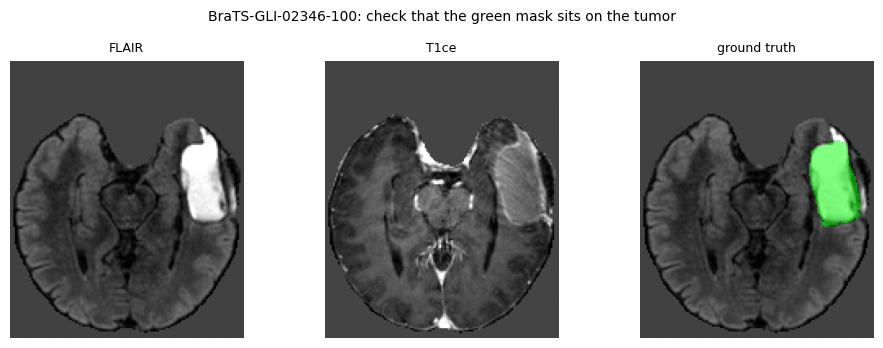

In [14]:
def load_nifti(path, as_label=False):
    """Load .nii / .nii.gz as a numpy array plus affine, reoriented to RAS so every patient has the same axis order."""
    img = nib.load(str(path))
    if REORIENT_TO_RAS:
        img = nib.as_closest_canonical(img)
    data = np.asarray(img.dataobj, dtype=np.float32)
    if as_label:
        data = np.rint(data).astype(np.uint8)
    return data, img.affine


def preprocess_volumes(vols, margin=2):
    """vols: list of 3D arrays (one per sequence). Returns the z-scored (C,D,H,W) float32 image cropped to the brain
    bounding box, the cropped brain mask and the crop slices."""
    x = np.stack(vols).astype(np.float32)
    brain = (x != 0).any(axis=0)                       # BraTS is skull-stripped: background is exactly 0
    if not brain.any():
        raise ValueError("empty scan")
    out = np.zeros_like(x)
    for c in range(x.shape[0]):
        v = x[c][brain]
        lo, hi = np.percentile(v, (0.5, 99.5))
        v = np.clip(v, lo, hi)
        out[c][brain] = (v - v.mean()) / (v.std() + 1e-6)   # z-score over brain voxels only
    idx = np.argwhere(brain)
    lo, hi = idx.min(0), idx.max(0) + 1
    sl = tuple(slice(int(max(a - margin, 0)), int(min(b + margin, s))) for a, b, s in zip(lo, hi, brain.shape))
    return out[(slice(None),) + sl], brain[sl], sl


def cache_case(rec, n_fg=20000, seed=0):
    cid = rec["id"]
    meta_path = CACHE_DIR / f"{cid}_meta.json"
    if meta_path.exists():
        return
    vols, affine = [], None
    for m in MODALITIES:
        d, a = load_nifti(rec[m])
        vols.append(d)
        affine = a if affine is None else affine
    img, _, sl = preprocess_volumes(vols)
    seg, _ = load_nifti(rec["seg"], as_label=True)
    seg = seg[sl]
    seg[seg == 4] = 3                                   # BraTS 2018-21 label 4 -> 3 (enhancing); BraTS 2023 already uses 3
    np.save(CACHE_DIR / f"{cid}_img.npy", img.astype(np.float16))
    np.save(CACHE_DIR / f"{cid}_seg.npy", seg)
    fg = np.argwhere(seg > 0)
    if len(fg) > n_fg:
        fg = fg[np.random.default_rng(seed).choice(len(fg), n_fg, replace=False)]
    np.save(CACHE_DIR / f"{cid}_fg.npy", fg.astype(np.int16))
    meta = {"id": cid, "shape": list(vols[0].shape), "bbox": [[int(s.start), int(s.stop)] for s in sl],
            "affine": affine.tolist(), "zooms": np.sqrt((affine[:3, :3] ** 2).sum(0)).tolist()}
    json.dump(meta, open(meta_path, "w"))               # written last, so a half-cached patient is redone next time


def best_slice(mask, axis=2):
    other = tuple(a for a in range(3) if a != axis)
    return int(np.argmax(mask.sum(axis=other))) if mask.any() else mask.shape[axis] // 2


def show_case(img, gt=None, pred=None, title="", axis=2):
    """img: (C,D,H,W). Shows FLAIR, T1ce and mask overlays on the axial slice with the most tumor."""
    ref = gt if gt is not None else pred
    k = best_slice(ref, axis) if ref is not None else img.shape[axis + 1] // 2
    take = lambda a: np.rot90(np.take(np.asarray(a, dtype=np.float32), k, axis=axis))
    flair = take(img[0])
    panels = [("FLAIR", flair, None, None), ("T1ce", take(img[2]), None, None)]
    if gt is not None:
        panels.append(("ground truth", flair, take(gt), "lime"))
    if pred is not None:
        panels.append(("prediction", flair, take(pred), "red"))
    fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.5))
    for ax, (name, bg, m, color) in zip(np.atleast_1d(axes), panels):
        ax.imshow(bg, cmap="gray"); ax.axis("off"); ax.set_title(name, fontsize=9)
        if m is not None and m.any():
            ax.imshow(np.ma.masked_where(m == 0, m), cmap=ListedColormap([color]), alpha=0.5, vmin=0, vmax=1)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


for rec in tqdm(cases, desc="caching patients"):
    cache_case(rec)
gb = sum(f.stat().st_size for f in CACHE_DIR.glob("*.npy")) / 2 ** 30
print(f"cache ready: {len(list(CACHE_DIR.glob('*_meta.json')))} patients, {gb:.2f} GB on disk")

# sanity check (always do this once): does the mask sit on the tumor?
cid0 = train_ids[0]
meta0 = json.load(open(CACHE_DIR / f"{cid0}_meta.json"))
img0 = np.load(CACHE_DIR / f"{cid0}_img.npy", mmap_mode="r")
seg0 = np.load(CACHE_DIR / f"{cid0}_seg.npy", mmap_mode="r")
print(f"{cid0}: original {meta0['shape']} -> cropped {list(img0.shape[1:])} | tumor voxels: {int((seg0 > 0).sum())} | spacing (mm): {np.round(meta0['zooms'], 2).tolist()}")
show_case(img0, gt=np.asarray(seg0) > 0, title=f"{cid0}: check that the green mask sits on the tumor")

## Step 3: Patch dataset (the only thing the training loop ever sees)

`BratsPatches` reads a random `patch³` window straight from the memory-mapped cache. With probability `fg_prob` the window is centred (with jitter) on a random tumor voxel; otherwise it is uniform, so the network also sees healthy tissue. Augmentation is deliberately cheap: random flips, per-sequence intensity scale/shift and occasional Gaussian noise, all applied only to brain voxels so the background stays exactly 0. (Add rotations or elastic deformation with MONAI or TorchIO if you have CPU to spare.)

In [7]:
@lru_cache(maxsize=48)
def _mm(path):                     # memory-mapped arrays; a few stay open per process
    return np.load(path, mmap_mode="r")


@lru_cache(maxsize=256)
def _fg(path):
    return np.load(path)


class BratsPatches(Dataset):
    """Random patches (training) or a fixed, reproducible set of patches (validation, when `seed` is given)."""

    def __init__(self, ids, patch, length, fg_prob=0.5, augment=True, seed=None):
        self.ids, self.P, self.length = list(ids), patch, length
        self.fg_prob, self.augment, self.seed = fg_prob, augment, seed
        self._rng = None

    def __len__(self):
        return self.length

    def _rng_for(self, idx):
        if self.seed is not None:                          # validation: identical patches every time
            return np.random.default_rng(self.seed + idx)
        if self._rng is None:                              # training: one independent RNG per DataLoader worker
            self._rng = np.random.default_rng(torch.initial_seed() % 2 ** 32)
        return self._rng

    def __getitem__(self, idx):
        rng, P = self._rng_for(idx), self.P
        cid = self.ids[idx % len(self.ids)] if self.seed is not None else self.ids[rng.integers(len(self.ids))]
        img, seg = _mm(str(CACHE_DIR / f"{cid}_img.npy")), _mm(str(CACHE_DIR / f"{cid}_seg.npy"))
        shape = np.array(seg.shape)
        hi = np.maximum(shape - P, 0)
        start = None
        if rng.random() < self.fg_prob:                    # centre the patch on a random tumor voxel (+ jitter)
            fg = _fg(str(CACHE_DIR / f"{cid}_fg.npy"))
            if len(fg):
                centre = fg[rng.integers(len(fg))].astype(int) + rng.integers(-P // 4, P // 4 + 1, size=3)
                start = centre - P // 2
        if start is None:
            start = rng.integers(0, hi + 1)
        start = np.clip(start, 0, hi)
        sl = tuple(slice(int(s), int(min(s + P, n))) for s, n in zip(start, shape))
        x = np.asarray(img[(slice(None),) + sl], dtype=np.float32)
        y = (np.asarray(seg[sl]) > 0).astype(np.float32)
        pad = [(0, P - s) for s in y.shape]                # volume smaller than the patch: zero-pad
        if any(p for _, p in pad):
            x, y = np.pad(x, [(0, 0)] + pad), np.pad(y, pad)
        if self.augment:
            for ax in range(3):
                if rng.random() < 0.5:
                    x, y = np.flip(x, ax + 1), np.flip(y, ax)
            brain = x != 0                                 # touch brain voxels only; background stays exactly 0
            scale = rng.uniform(0.9, 1.1, (x.shape[0], 1, 1, 1)).astype(np.float32)
            shift = rng.uniform(-0.1, 0.1, (x.shape[0], 1, 1, 1)).astype(np.float32)
            x = np.where(brain, x * scale + shift, 0.0)
            if rng.random() < 0.3:
                x = x + rng.normal(0, 0.03, x.shape).astype(np.float32) * brain
        return (torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)),
                torch.from_numpy(np.ascontiguousarray(y[None], dtype=np.float32)))


# quick look at one batch
_xb, _yb = next(iter(DataLoader(BratsPatches(train_ids, cfg.patch, 8, cfg.fg_prob), batch_size=4)))
print(f"batch x {tuple(_xb.shape)}, y {tuple(_yb.shape)} | tumor fraction of patch voxels: {100 * _yb.mean().item():.2f}% | input mean/std: {_xb.mean().item():.2f} / {_xb.std().item():.2f}")

batch x (4, 4, 96, 96, 96), y (4, 1, 96, 96, 96) | tumor fraction of patch voxels: 5.20% | input mean/std: 0.04 / 0.85


## Step 4: The model, a lean 3D U-Net

4 levels (`base`, 2·`base`, 4·`base`, 8·`base` channels), two `3×3×3 conv → InstanceNorm → LeakyReLU` per level, strided-conv downsampling, transposed-conv upsampling, concatenation skips, and **deep supervision** (extra 1×1×1 heads at ½ and ¼ resolution during training). Activation memory is dominated by the full-resolution level (`C₀·V₀`), so the width of that level (`base`) is the main memory and compute knob.

Loss = BCE + soft Dice (computed over the whole batch, because many patches contain no tumor), summed over the three output scales with weights ∝ 1/2ᵏ.

In [8]:
class ConvBlock(nn.Sequential):
    """(3x3x3 conv -> InstanceNorm -> LeakyReLU) x 2"""

    def __init__(self, cin, cout):
        layers = []
        for i in range(2):
            layers += [nn.Conv3d(cin if i == 0 else cout, cout, 3, padding=1, bias=False),
                       nn.InstanceNorm3d(cout, affine=True),
                       nn.LeakyReLU(0.01, inplace=True)]
        super().__init__(*layers)


class LeanUNet3D(nn.Module):
    def __init__(self, in_ch=4, out_ch=1, base=16, levels=4, deep_supervision=True, use_ckpt=False):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels)]                      # e.g. 16-32-64-128
        self.levels, self.ds, self.use_ckpt = levels, deep_supervision, use_ckpt
        self.enc = nn.ModuleList([ConvBlock(in_ch if i == 0 else ch[i - 1], ch[i]) for i in range(levels)])
        self.down = nn.ModuleList([nn.Conv3d(ch[i], ch[i], 2, stride=2, bias=False) for i in range(levels - 1)])
        rev = list(reversed(range(levels - 1)))                          # decoder levels, deepest first
        self.up = nn.ModuleList([nn.ConvTranspose3d(ch[i + 1], ch[i], 2, stride=2) for i in rev])
        self.dec = nn.ModuleList([ConvBlock(2 * ch[i], ch[i]) for i in rev])
        self.heads = nn.ModuleList([nn.Conv3d(ch[i], out_ch, 1) for i in rev])
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, a=0.01, nonlinearity="leaky_relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def _run(self, block, x):
        if self.use_ckpt and self.training:                              # recompute activations in backward
            return checkpoint(block, x, use_reentrant=False)
        return block(x)

    def forward(self, x):
        skips = []
        for i in range(self.levels - 1):
            x = self._run(self.enc[i], x)
            skips.append(x)
            x = self.down[i](x)
        x = self._run(self.enc[-1], x)
        outs = []
        for j in range(self.levels - 1):                                 # deepest -> full resolution
            x = self.up[j](x)
            x = torch.cat([skips[self.levels - 2 - j], x], dim=1)
            x = self._run(self.dec[j], x)
            if self.ds and self.training:
                outs.append(self.heads[j](x))
        return outs[::-1] if (self.ds and self.training) else self.heads[-1](x)   # train: [full, 1/2, 1/4]; eval: full


def soft_dice_loss(logits, target, smooth=1.0):
    p = torch.sigmoid(logits)
    dims = (0, 2, 3, 4)                                   # batch-level Dice: stable when a patch has no tumor
    inter = (p * target).sum(dims)
    denom = p.sum(dims) + target.sum(dims)
    return (1 - (2 * inter + smooth) / (denom + smooth)).mean()


def deep_sup_loss(outs, target):
    outs = outs if isinstance(outs, (list, tuple)) else [outs]
    w = torch.tensor([0.5 ** k for k in range(len(outs))])
    w = (w / w.sum()).tolist()
    total = 0.0
    for wk, o in zip(w, outs):
        o = o.float()
        t = target if o.shape[2:] == target.shape[2:] else F.interpolate(target, size=o.shape[2:], mode="nearest")
        total = total + wk * (F.binary_cross_entropy_with_logits(o, t) + soft_dice_loss(o, t))
    return total


def count_params(m):
    return sum(p.numel() for p in m.parameters())


_m = LeanUNet3D(4, 1, cfg.base, cfg.levels, True, cfg.ckpt)
print(f"parameters: {count_params(_m) / 1e6:.2f} M  (~{count_params(_m) * 4 / 2 ** 20:.1f} MB in fp32)")
_x = torch.randn(1, 4, cfg.patch, cfg.patch, cfg.patch)
_m.train(); print("train-mode output shapes:", [tuple(o.shape[2:]) for o in _m(_x)])
_m.eval()
with torch.no_grad():
    print("eval-mode output shape:  ", tuple(_m(_x).shape[2:]))
del _m, _x

parameters: 1.45 M  (~5.5 MB in fp32)
train-mode output shapes: [(96, 96, 96), (48, 48, 48), (24, 24, 24)]
eval-mode output shape:   (96, 96, 96)


## Step 5: Benchmark one training step (optional but recommended)

Prints the time per step and, on a GPU, the peak memory, so you can tune `patch`, `base`, `batch_size`, `amp`, `ckpt` and `accum` *before* committing to a long run.

In [9]:
def benchmark(cfg, steps=4):
    use_amp = cfg.amp and DEVICE.type == "cuda"
    m = LeanUNet3D(4, 1, cfg.base, cfg.levels, True, cfg.ckpt).to(DEVICE).train()
    opt, scaler = torch.optim.AdamW(m.parameters(), 1e-3), make_scaler(use_amp)
    x = torch.randn(cfg.batch_size, 4, *[cfg.patch] * 3, device=DEVICE)
    y = (torch.rand(cfg.batch_size, 1, *[cfg.patch] * 3, device=DEVICE) > 0.97).float()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    times = []
    try:
        for _ in range(steps):
            t0 = time.time()
            opt.zero_grad(set_to_none=True)
            with amp_ctx(DEVICE, use_amp):
                outs = m(x)
            scaler.scale(deep_sup_loss(outs, y)).backward()
            scaler.step(opt); scaler.update()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            times.append(time.time() - t0)
    except RuntimeError as e:
        if "out of memory" not in str(e).lower():
            raise
        print("OUT OF MEMORY -> lower cfg.patch / cfg.base / cfg.batch_size, set cfg.ckpt = True, or use cfg.accum > 1")
        return
    t = float(np.median(times[1:])) if len(times) > 1 else times[0]
    peak = f" | peak GPU memory {torch.cuda.max_memory_allocated() / 2 ** 30:.2f} GB" if DEVICE.type == "cuda" else ""
    print(f"{t:.2f} s per micro-step (batch {cfg.batch_size}, patch {cfg.patch}³){peak}")
    print(f"=> {cfg.total_steps} optimizer steps x {cfg.accum} micro-step(s) is about {t * cfg.total_steps * cfg.accum / 60:.0f} min of training")
    del m, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


benchmark(cfg)

0.17 s per micro-step (batch 2, patch 96³) | peak GPU memory 1.80 GB
=> 6000 optimizer steps x 1 micro-step(s) is about 17 min of training


## Step 6: Train

AdamW with a poly learning-rate decay `lr(t) = lr₀·(1 − t/T)^0.9`, gradient clipping at 12, optional fp16 autocast, gradient accumulation (`cfg.accum`), and checkpoint/resume (`ckpt/last.pt`; the best model by validation Dice goes to `ckpt/best.pt`). Validation uses a **fixed set of validation patches** (cheap) and reports patch-level Dice; the proper full-scan evaluation happens in Step 8 on held-out test patients.

Stop the cell any time and re-run it: training resumes from `last.pt`, which is written every `val_every` steps (set `RESUME = False` to start over).

In [10]:
import torch

@torch.no_grad()
def validate(model, loader, use_amp):
    model.eval()
    inter = p_sum = g_sum = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with amp_ctx(DEVICE, use_amp):
            logits = model(x)
        pred = (torch.sigmoid(logits.float()) > 0.5).float()
        inter += (pred * y).sum().item(); p_sum += pred.sum().item(); g_sum += y.sum().item()
    model.train()
    return (2 * inter + 1e-5) / (p_sum + g_sum + 1e-5)


def train(cfg, train_ids, val_ids, resume=True):
    use_amp = cfg.amp and DEVICE.type == "cuda"
    model = LeanUNet3D(4, 1, cfg.base, cfg.levels, True, cfg.ckpt).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(1.0 - s / cfg.total_steps, 0.0) ** 0.9)   # poly decay
    scaler = make_scaler(use_amp)
    step, best, hist = 0, -1.0, {"step": [], "loss": [], "val_step": [], "val_dice": []}
    last = CKPT_DIR / "last.pt"
    if resume and last.exists():
        ck = load_ckpt(last)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); step, best, hist = ck["step"], ck["best"], ck["hist"]
        print(f"resumed from step {step} (best validation Dice so far {best:.3f})")

    ds = BratsPatches(train_ids, cfg.patch, cfg.steps_per_epoch * cfg.accum * cfg.batch_size, cfg.fg_prob, augment=True)
    dl = DataLoader(ds, batch_size=cfg.batch_size, num_workers=cfg.num_workers, drop_last=True,
                    pin_memory=DEVICE.type == "cuda", persistent_workers=cfg.num_workers > 0)
    vdl = DataLoader(BratsPatches(val_ids, cfg.patch, cfg.val_patches, cfg.fg_prob, augment=False, seed=1234),
                     batch_size=cfg.batch_size, num_workers=0)

    def save(path):
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "step": step, "best": best, "hist": hist, "cfg": asdict(cfg)}, path)

    model.train()
    micro, run, t0, start_step = 0, [], time.time(), step
    while step < cfg.total_steps:
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with amp_ctx(DEVICE, use_amp):
                outs = model(x)
            loss = deep_sup_loss(outs, y)
            scaler.scale(loss / cfg.accum).backward()
            run.append(loss.item())
            micro += 1
            if micro % cfg.accum:
                continue                                   # keep accumulating gradients
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            step += 1
            if step % cfg.log_every == 0:
                hist["step"].append(step); hist["loss"].append(float(np.mean(run))); run = []
                el = time.time() - t0
                eta = el / (step - start_step) * (cfg.total_steps - step)
                print(f"step {step:5d}/{cfg.total_steps} | loss {hist['loss'][-1]:.4f} | lr {sched.get_last_lr()[0]:.2e} | {el / 60:.1f} min elapsed, ~{eta / 60:.1f} min left")
            if step % cfg.val_every == 0 or step == cfg.total_steps:
                d = validate(model, vdl, use_amp)
                hist["val_step"].append(step); hist["val_dice"].append(d)
                if d > best:
                    best = d
                    save(CKPT_DIR / "best.pt")
                save(CKPT_DIR / "last.pt")
                print(f"   validation patch-Dice {d:.4f} (best {best:.4f})")
            if step >= cfg.total_steps:
                break
    return model, hist


RESUME = True

_required = {"cfg", "train_ids", "val_ids", "LeanUNet3D", "CKPT_DIR", "DEVICE"}
_missing = sorted(_required.difference(globals()))
if _missing:
    raise RuntimeError(
        "Training prerequisites are missing: " + ", ".join(_missing) + ". "
        "Notebook outputs do not restore Python state; run all cells from Step 0 downward, then rerun Step 6."
    )

model, hist = train(cfg, train_ids, val_ids, resume=RESUME)

step    25/6000 | loss 1.4585 | lr 9.96e-04 | 0.2 min elapsed, ~59.2 min left
step    50/6000 | loss 1.2777 | lr 9.92e-04 | 0.5 min elapsed, ~59.1 min left
step    75/6000 | loss 1.1386 | lr 9.89e-04 | 0.7 min elapsed, ~59.0 min left
step   100/6000 | loss 1.1073 | lr 9.85e-04 | 1.0 min elapsed, ~58.4 min left
step   125/6000 | loss 1.0453 | lr 9.81e-04 | 1.2 min elapsed, ~58.0 min left
step   150/6000 | loss 0.9512 | lr 9.77e-04 | 1.5 min elapsed, ~57.3 min left
step   175/6000 | loss 0.9003 | lr 9.74e-04 | 1.7 min elapsed, ~56.6 min left
step   200/6000 | loss 0.8848 | lr 9.70e-04 | 1.9 min elapsed, ~55.8 min left
step   225/6000 | loss 0.7431 | lr 9.66e-04 | 2.1 min elapsed, ~55.1 min left
step   250/6000 | loss 0.7670 | lr 9.62e-04 | 2.4 min elapsed, ~54.7 min left
step   275/6000 | loss 0.8296 | lr 9.59e-04 | 2.6 min elapsed, ~54.1 min left
step   300/6000 | loss 0.7624 | lr 9.55e-04 | 2.9 min elapsed, ~54.2 min left
step   325/6000 | loss 0.6651 | lr 9.51e-04 | 3.1 min elapsed, ~

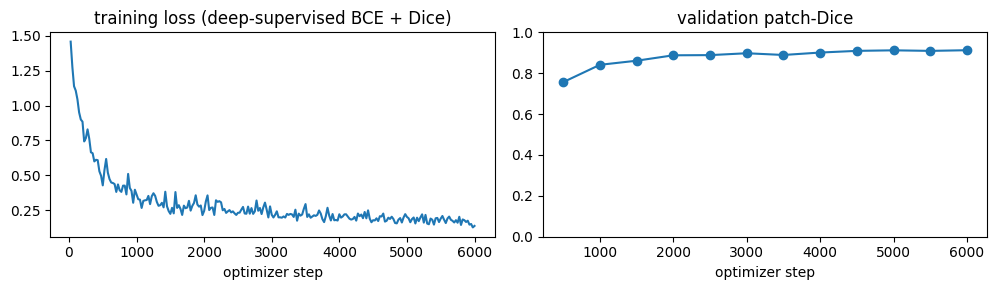

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist["step"], hist["loss"]); ax[0].set_title("training loss (deep-supervised BCE + Dice)"); ax[0].set_xlabel("optimizer step")
ax[1].plot(hist["val_step"], hist["val_dice"], marker="o"); ax[1].set_title("validation patch-Dice"); ax[1].set_xlabel("optimizer step"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## Step 7: Sliding-window inference

The whole scan never goes through the network. With window size `p`, stride `s = p·(1 − overlap)` and scan length `L` along an axis:

```
N      = ceil((L - p) / s) + 1                 windows per axis
start  = min(k·s, L - p)                       last window is pushed back so it ends flush with the scan
w(x)   = exp(-|x - centre|² / 2σ²),  σ = p/8   Gaussian importance map: trust window centres, not borders
P(x)   = Σ_k w_k(x)·P_k(x) / Σ_k w_k(x)        blended probability
```

Implementation notes: two fp32 accumulators (`prob_sum`, `weight_sum`) live in RAM, so only one window batch is ever on the GPU; weights are clamped at 1e-6 because corner weights underflow in fp16; windows with almost no brain are skipped; optional flip test-time augmentation averages up to 4 views per window. The self-test below checks the stitching math without any model: if every window just returns the input, the stitched output must reproduce the input exactly.

In [12]:
def window_starts(L, p, stride):
    """Start index of every window along one axis; the last window is pushed back so it ends flush with the scan."""
    if L <= p:
        return [0]
    n = math.ceil((L - p) / stride) + 1
    return sorted({min(k * stride, L - p) for k in range(n)})


def count_windows(shape, p, overlap):
    stride = max(1, int(p * (1 - overlap)))
    return int(np.prod([len(window_starts(s, p, stride)) for s in shape]))


def gaussian_map(p, sigma_scale=1 / 8):
    ax = np.arange(p) - (p - 1) / 2
    g = np.exp(-ax ** 2 / (2 * (p * sigma_scale) ** 2))
    w = g[:, None, None] * g[None, :, None] * g[None, None, :]
    return np.maximum(w / w.max(), 1e-6).astype(np.float32)


def make_predict_fn(model, use_amp=False):
    model.eval()

    def fn(x):
        with amp_ctx(DEVICE, use_amp):
            logits = model(x)
        return torch.sigmoid(logits.float())
    return fn


@torch.no_grad()
def sliding_window_predict(img, predict_fn, patch, overlap=0.5, sw_batch=1, brain=None,
                           min_brain_frac=0.01, flips=((),), device=None):
    """img: (C,D,H,W) array (a memmap is fine). predict_fn: tensor (B,C,p,p,p) -> probabilities (B,1,p,p,p).
    Returns the stitched probability map (D,H,W) as float32."""
    device = device or DEVICE
    C, D, H, W = img.shape
    P = patch
    if min(D, H, W) < P:                                   # tiny volume: zero-pad up to one window
        padw = [(0, 0)] + [(0, max(P - s, 0)) for s in (D, H, W)]
        img = np.pad(np.asarray(img, dtype=np.float32), padw)
        brain = None if brain is None else np.pad(brain, padw[1:])
    shape = img.shape[1:]
    stride = max(1, int(P * (1 - overlap)))
    coords = [(z, y, x) for z in window_starts(shape[0], P, stride)
              for y in window_starts(shape[1], P, stride)
              for x in window_starts(shape[2], P, stride)]
    if brain is not None:                                  # skip windows with (almost) no brain
        coords = [c for c in coords if brain[c[0]:c[0] + P, c[1]:c[1] + P, c[2]:c[2] + P].mean() >= min_brain_frac]
    wmap = gaussian_map(P)
    wmap_t = torch.from_numpy(wmap).to(device)
    prob, wsum = np.zeros(shape, np.float32), np.zeros(shape, np.float32)
    for i in range(0, len(coords), sw_batch):
        batch = coords[i:i + sw_batch]
        xb = np.stack([np.asarray(img[:, z:z + P, y:y + P, x:x + P], dtype=np.float32) for z, y, x in batch])
        xb = torch.from_numpy(xb).to(device)
        acc = 0
        for fl in flips:                                   # optional flip test-time augmentation
            dims = [d + 2 for d in fl]
            out = predict_fn(torch.flip(xb, dims) if fl else xb)
            acc = acc + (torch.flip(out, dims) if fl else out)
        pb = ((acc / len(flips))[:, 0] * wmap_t).cpu().numpy()
        for (z, y, x), p_ in zip(batch, pb):
            prob[z:z + P, y:y + P, x:x + P] += p_
            wsum[z:z + P, y:y + P, x:x + P] += wmap
    out = np.divide(prob, wsum, out=np.zeros_like(prob), where=wsum > 0)
    return out[:D, :H, :W]


# ---- self-test of the stitching code (no model needed)
_vol = np.random.default_rng(0).random((4, 150, 170, 130), dtype=np.float32)
for _ov in (0.5, 0.25, 0.0):
    _rec = sliding_window_predict(_vol, lambda x: x[:, :1], patch=64, overlap=_ov, device=torch.device("cpu"))
    assert np.allclose(_rec, _vol[0], atol=1e-5), f"stitching is broken at overlap={_ov}"
print("stitching self-test passed")
print("windows for a 160x192x144 brain box with a 96³ patch:", {f"{int(o * 100)}% overlap": count_windows((160, 192, 144), 96, o) for o in (0.5, 0.25, 0.0)})

stitching self-test passed
windows for a 160x192x144 brain box with a 96³ patch: {'50% overlap': 18, '25% overlap': 12, '0% overlap': 8}


## Step 8: Inference on held-out patients

For each test patient: sliding-window prediction → threshold + remove tiny components → Dice, HD95 (95th-percentile Hausdorff distance in mm), tumor volumes → overlay figure → mask written as `.nii.gz` into `brats_work/predictions/`. Masks are saved in RAS orientation with the scan's world coordinates, so any viewer (ITK-SNAP, 3D Slicer) overlays them correctly on the original scan. The prediction runs on the cached, preprocessed scan; Step 9 shows the same thing starting from the raw `.nii` files. BraTS gliomas are usually one connected mass, so `KEEP_LARGEST = True` often removes stray false positives, especially from an under-trained model.

loaded best.pt: step 6000, validation patch-Dice 0.912, patch 96³


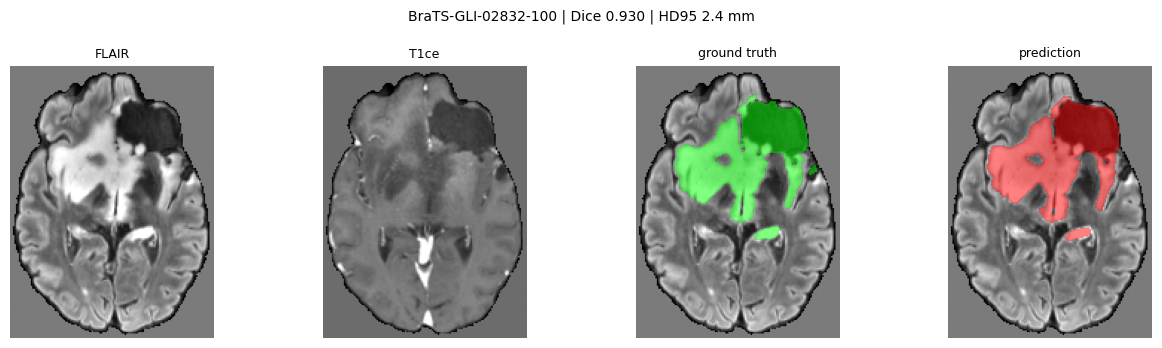

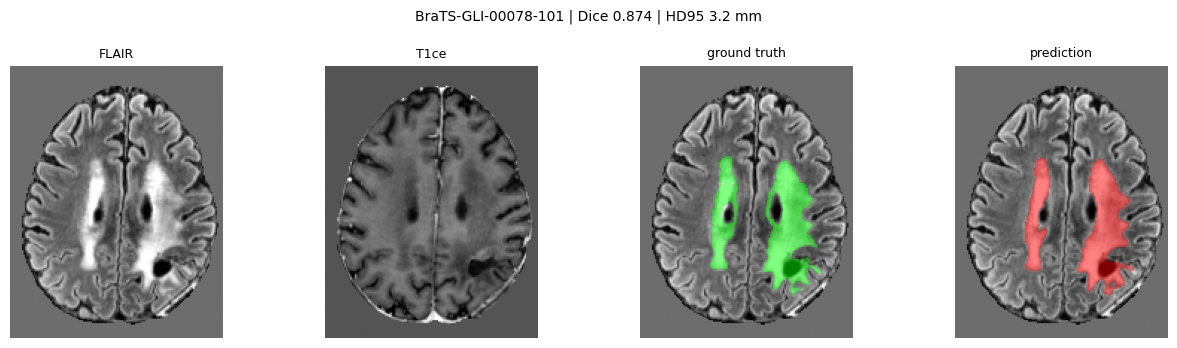

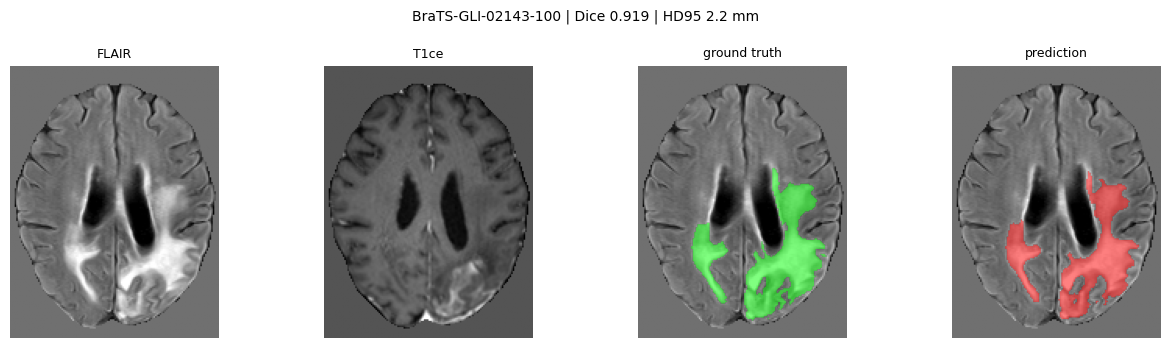

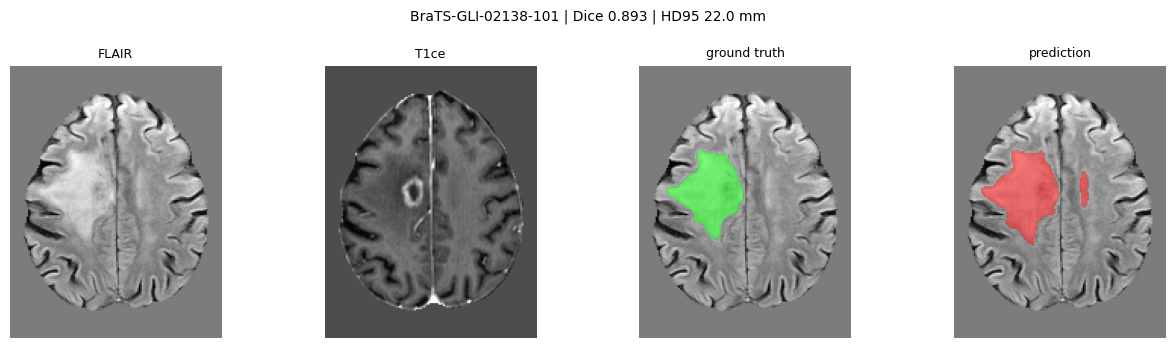

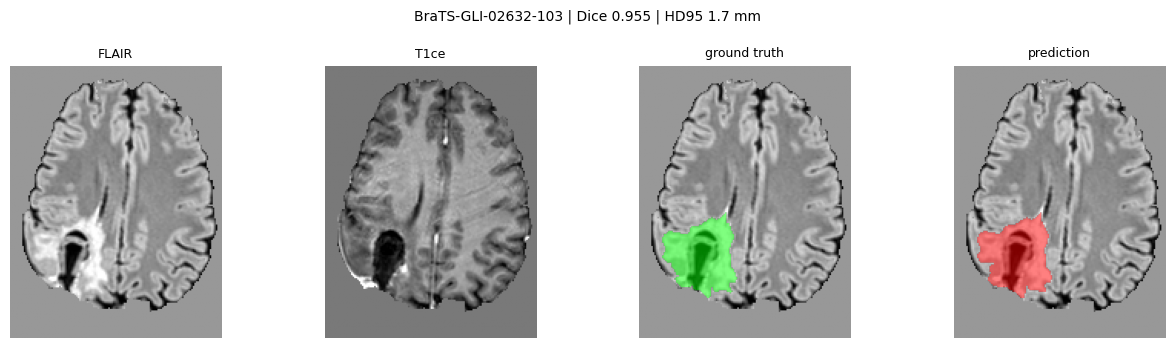

                      dice  hd95_mm    gt_ml  pred_ml  windows  seconds
patient                                                                
BraTS-GLI-02832-100  0.930    2.449  133.314  139.829       12    0.975
BraTS-GLI-00078-101  0.874    3.162   76.604   68.802       12    0.789
BraTS-GLI-02143-100  0.919    2.236  129.940  116.301       18    1.138
BraTS-GLI-02138-101  0.893   22.045   53.593   63.127       18    1.004
BraTS-GLI-02632-103  0.955    1.732   71.282   74.073       12    0.878

mean Dice 0.914 | median HD95 2.4 mm | masks saved in brats_work\predictions


In [15]:
def postprocess(prob, thr=0.5, min_size=300, keep_largest=False):
    """Threshold, drop connected components smaller than `min_size` voxels, optionally keep only the largest one."""
    m = prob > thr
    lab, n = ndi.label(m)
    if n:
        sizes = np.bincount(lab.ravel())[1:]
        keep = np.flatnonzero(sizes >= min_size)
        if keep_largest and len(keep):
            keep = keep[[np.argmax(sizes[keep])]]
        m = np.isin(lab, 1 + keep)
    return m


def dice_np(p, g, eps=1e-8):
    return float((2 * (p & g).sum() + eps) / (p.sum() + g.sum() + eps))


def hd95(p, g, spacing=(1, 1, 1)):
    if not p.any() or not g.any():
        return float("nan")
    ps, gs = p & ~ndi.binary_erosion(p), g & ~ndi.binary_erosion(g)         # surface voxels
    d_to_g = ndi.distance_transform_edt(~gs, sampling=spacing)
    d_to_p = ndi.distance_transform_edt(~ps, sampling=spacing)
    return float(np.percentile(np.concatenate([d_to_g[ps], d_to_p[gs]]), 95))


def save_mask_nifti(mask_cropped, meta, path):
    """Paste the cropped mask back into the full (RAS) frame and save it with the original affine."""
    full = np.zeros(meta["shape"], np.uint8)
    full[tuple(slice(a, b) for a, b in meta["bbox"])] = mask_cropped
    nib.save(nib.Nifti1Image(full, np.array(meta["affine"])), str(path))


# ---- load the best checkpoint (the window size must equal the training patch size)
ck = load_ckpt(CKPT_DIR / "best.pt")
tcfg = ck["cfg"]
PATCH = tcfg["patch"]
best_model = LeanUNet3D(4, 1, tcfg["base"], tcfg["levels"], True, False).to(DEVICE)
best_model.load_state_dict(ck["model"])
predict_fn = make_predict_fn(best_model, use_amp=cfg.amp)
print(f"loaded best.pt: step {ck['step']}, validation patch-Dice {ck['best']:.3f}, patch {PATCH}³")

FLIP_TTA = False        # True = 4 passes per window (original + a flip along each axis): slower, slightly smoother
flips = ((), (0,), (1,), (2,)) if FLIP_TTA else ((),)
KEEP_LARGEST = False    # True = keep only the biggest connected component (gliomas are usually one mass; leave off for multifocal disease)
N_INFER = 5             # how many held-out patients to run (set to len(test_ids) for the whole test split)

rows = []
for cid in test_ids[:N_INFER]:
    meta = json.load(open(CACHE_DIR / f"{cid}_meta.json"))
    img = np.load(CACHE_DIR / f"{cid}_img.npy", mmap_mode="r")
    gt = np.load(CACHE_DIR / f"{cid}_seg.npy") > 0
    brain = np.asarray(img[0] != 0)
    t0 = time.time()
    prob = sliding_window_predict(img, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, brain=brain, flips=flips)
    pred = postprocess(prob, thr=0.5, min_size=300, keep_largest=KEEP_LARGEST)
    secs = time.time() - t0
    ml = float(np.prod(meta["zooms"])) / 1000                               # mL per voxel
    rows.append({"patient": cid, "dice": dice_np(pred, gt), "hd95_mm": hd95(pred, gt, meta["zooms"]),
                 "gt_ml": gt.sum() * ml, "pred_ml": pred.sum() * ml,
                 "windows": count_windows(img.shape[1:], PATCH, cfg.overlap), "seconds": secs})
    save_mask_nifti(pred, meta, PRED_DIR / f"{cid}_pred.nii.gz")
    show_case(img, gt=gt, pred=pred, title=f"{cid} | Dice {rows[-1]['dice']:.3f} | HD95 {rows[-1]['hd95_mm']:.1f} mm")

results = pd.DataFrame(rows).set_index("patient")
print(results.round(3).to_string())
print(f"\nmean Dice {results['dice'].mean():.3f} | median HD95 {results['hd95_mm'].median():.1f} mm | masks saved in {PRED_DIR}")

## Step 9: From raw `.nii` files to a tumor mask (what you would run on a new patient)

`predict_nifti_case` does everything from scratch for one patient: load the four sequences → the same preprocessing as the cache → sliding-window inference → post-processing → mask pasted back into the full scan and written as NIfTI. No segmentation file is needed. The scans must be like BraTS: skull-stripped (background exactly 0), co-registered across sequences and about 1 mm isotropic.

The demo runs it on the first test patient's raw files and compares with the ground truth. To run it on unlabeled data (for example the BraTS validation set, which ships without segmentations), set `VALIDATION_DIR`.

In [16]:
def predict_nifti_case(paths, model_fn, patch, overlap=0.5, sw_batch=1, flips=((),), thr=0.5, min_size=300, keep_largest=False, out_path=None):
    """paths: dict with keys flair / t1 / t1ce / t2 -> .nii or .nii.gz files of ONE patient."""
    vols, affine = [], None
    for m in MODALITIES:
        d, a = load_nifti(paths[m])
        vols.append(d)
        affine = a if affine is None else affine
    img, brain, sl = preprocess_volumes(vols)
    prob = sliding_window_predict(img, model_fn, patch, overlap, sw_batch, brain=brain, flips=flips)
    mask = postprocess(prob, thr, min_size, keep_largest)
    full = np.zeros(vols[0].shape, np.uint8)
    full[sl] = mask
    if out_path is not None:
        nib.save(nib.Nifti1Image(full, affine), str(out_path))
    return {"mask": full, "affine": affine, "img": img, "sl": sl, "prob": prob}


rec = by_id[test_ids[0]]
out = predict_nifti_case(rec, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, flips, keep_largest=KEEP_LARGEST, out_path=PRED_DIR / f"{rec['id']}_from_raw.nii.gz")
gt_raw, _ = load_nifti(rec["seg"], as_label=True)
print(f"{rec['id']}: tumor volume {out['mask'].sum() / 1000:.1f} mL | Dice vs ground truth {dice_np(out['mask'] > 0, gt_raw > 0):.3f}")
print("written:", PRED_DIR / f"{rec['id']}_from_raw.nii.gz")

VALIDATION_DIR = None     # e.g. Path("./data/BraTS2020_ValidationData"): patients WITHOUT segmentation files
if VALIDATION_DIR is not None:
    for rec in find_cases(VALIDATION_DIR, need_seg=False, max_cases=3):
        out = predict_nifti_case(rec, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, flips, keep_largest=KEEP_LARGEST, out_path=PRED_DIR / f"{rec['id']}_pred.nii.gz")
        show_case(out["img"], pred=out["mask"][out["sl"]] > 0, title=f"{rec['id']} (no ground truth): predicted tumor {out['mask'].sum() / 1000:.1f} mL")

BraTS-GLI-02832-100: tumor volume 139.8 mL | Dice vs ground truth 0.930
written: brats_work\predictions\BraTS-GLI-02832-100_from_raw.nii.gz


## Where to go from here

- **Train longer / on more data.** The default schedules are short; validation Dice usually keeps improving with more steps. Use the `gpu_low` or `gpu_mid` preset on a GPU, or a free Kaggle / Colab GPU (the notebook runs there unchanged, just point `DATA_ROOT` at the dataset).
- **Sub-regions** (necrotic core / edema / enhancing tumor): the cache already stores the 0–3 label map. Return a multi-channel target from `BratsPatches`, use `out_ch=3` and region-based sigmoids (whole tumor / tumor core / enhancing).
- **Cheaper inference.** Lower `cfg.overlap`, raise `cfg.sw_batch` as far as memory allows, keep empty-window skipping on. A coarse-to-fine cascade (a 2 mm whole-brain pass, then full-resolution windows only around detections) and INT8 / ONNX export are the next steps.
- **Better accuracy.** 5-fold cross-validation by patient, rotation / scale augmentation, longer schedules, ensembling the folds.
- This is research / educational code, not a medical device. Do not use it for clinical decisions.